In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression

import pickle

import xgboost as xgb
print(xgb.__version__)

3.2.0


In [2]:
train = pd.read_csv('../Data/train_imputed.csv')
oot1 = pd.read_csv('../Data/oot1_imputed.csv')
oot2 = pd.read_csv('../Data/oot2_imputed.csv')

feats_to_drop = pickle.load(open('../Files/selected_features.csv', 'rb'))['final_features_to_drop']

id_vars = ['id', 'data_type', 'HQ_city', 'ateco_sector']
target_var = 'default'
feature_vars = [col for col in train.columns if col not in id_vars + [target_var] + feats_to_drop]
categorical_features = ['legal_structure_category', 'sector_category']

train[categorical_features] = train[categorical_features].astype('string')
oot1[categorical_features] = oot1[categorical_features].astype('string')
oot2[categorical_features] = oot2[categorical_features].astype('string')
print(train.shape, oot1.shape, oot2.shape)

(475389, 30) (174229, 30) (183730, 30)


In [3]:
ID_train = train[id_vars + [target_var] + categorical_features]
X_train = train[feature_vars]
y_train = train[target_var]

ID_oot1 = oot1[id_vars + [target_var] + categorical_features]
X_oot1 = oot1[feature_vars]
y_oot1 = oot1[target_var]

ID_oot2 = oot2[id_vars + [target_var] + categorical_features]
X_oot2 = oot2[feature_vars]
y_oot2 = oot2[target_var]

In [4]:
category_types = {}

for col in categorical_features:
    dtype = pd.CategoricalDtype(
        categories=X_train[col].dropna().unique()
    )
    category_types[col] = dtype

    X_train[col] = X_train[col].astype(dtype)
    X_oot1[col] = X_oot1[col].astype(dtype)
    X_oot2[col] = X_oot2[col].astype(dtype)

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_91336/217081448.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train[col] = X_train[col].astype(dtype)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_91336/217081448.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_oot1[col] = X_oot1[col].astype(dtype)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_91336/217081448.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
T

In [5]:
logit = LogisticRegression(
    solver='lbfgs',
    C=1.0,
    max_iter=5000,
    tol=1e-4
)

In [6]:
vars_without_cat = [f for f in feature_vars if f not in categorical_features]

In [10]:
logit.fit(X_train[vars_without_cat], y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,5000
,multi_class,'deprecated'


In [11]:
pickle.dump(logit, open('../Artifacts/logit_model_ratio_and_flag_features_imputed.pkl', 'wb'))

In [12]:
train_pred = logit.predict_proba(X_train[vars_without_cat])[:, 1]
oot1_pred = logit.predict_proba(X_oot1[vars_without_cat])[:, 1]
oot2_pred = logit.predict_proba(X_oot2[vars_without_cat].dropna())[:, 1]

In [17]:
scores_train = pd.concat([ID_train, pd.DataFrame({'y_true': y_train, 'y_pred': train_pred})], axis=1)
scores_oot1 = pd.concat([ID_oot1, pd.DataFrame({'y_true': y_oot1, 'y_pred': oot1_pred})], axis=1)
scores_oot2 = pd.concat([ID_oot2.loc[X_oot2[vars_without_cat].dropna().index], pd.DataFrame({'y_true': y_oot2.loc[X_oot2[vars_without_cat].dropna().index], 'y_pred': oot2_pred})], axis=1)

In [19]:
scores_train.to_csv('../Model_scores/scores_train_imputed_logit.csv', index=False)
scores_oot1.to_csv('../Model_scores/scores_oot1_imputed_logit.csv', index=False)
scores_oot2.to_csv('../Model_scores/scores_oot2_imputed_logit.csv', index=False)

# features[id_vars + categorical_features].to_csv('../Model_scores/categorical_features.csv', index=False)

In [20]:
roc_auc_train = roc_auc_score(scores_train['y_true'], scores_train['y_pred'])
roc_auc_oot1 = roc_auc_score(scores_oot1['y_true'], scores_oot1['y_pred'])
roc_auc_oot2 = roc_auc_score(scores_oot2['y_true'], scores_oot2['y_pred'])

print(f"Train ROC AUC: {roc_auc_train:.4f}")
print(f"oot1 ROC AUC: {roc_auc_oot1:.4f}")
print(f"OOT2 ROC AUC: {roc_auc_oot2:.4f}")

Train ROC AUC: 0.5212
oot1 ROC AUC: 0.5236
OOT2 ROC AUC: 0.5376


In [21]:
fpr_train, tpr_train, thresholds_train = roc_curve(scores_train['y_true'], scores_train['y_pred'])
fpr_oot1, tpr_oot1, thresholds_oot1 = roc_curve(scores_oot1['y_true'], scores_oot1['y_pred'])
fpr_oot2, tpr_oot2, thresholds_oot2 = roc_curve(scores_oot2['y_true'], scores_oot2['y_pred'])

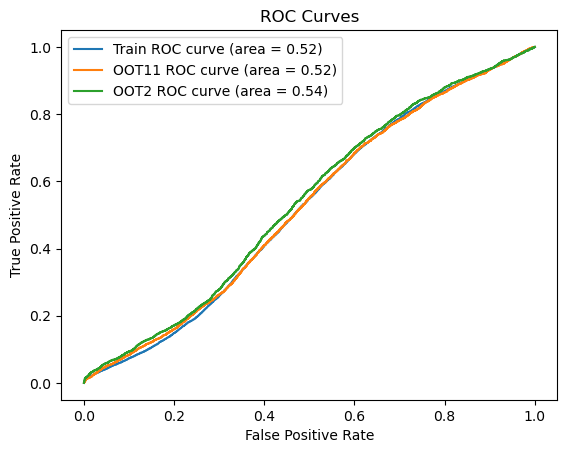

In [22]:
plt.plot(fpr_train, tpr_train, label='Train ROC curve (area = %0.2f)' % roc_auc_score(scores_train['y_true'], scores_train['y_pred']))
plt.plot(fpr_oot1, tpr_oot1, label='OOT11 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot1['y_true'], scores_oot1['y_pred']))
plt.plot(fpr_oot2, tpr_oot2, label='OOT2 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot2['y_true'], scores_oot2['y_pred']))
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.show()

In [29]:
vars_without_cat

['net_profit_assets',
 'operating_profit_assets',
 'operating_margin',
 'roe',
 'working_capital_assets',
 'cash_assets',
 'cash_short_term_debt',
 'equity_assets',
 'short_term_debt_assets',
 'interest_coverage_proxy',
 'operating_cashflow_assets',
 'cashflow_liabilities_proxy',
 'sales_assets',
 'receivables_assets',
 'receivables_days_proxy']

In [30]:
summary = pd.DataFrame({
    'feature': vars_without_cat,
    'coefficient': logit.coef_[0],
    'odds_ratio': np.exp(logit.coef_[0])
})

summary = summary.sort_values(
    'coefficient', key=abs, ascending=False
)

print('Intercept:', logit.intercept_[0])
display(summary)

Intercept: -1.8867666639775411


,feature,coefficient,odds_ratio
6,cash_short_term_debt,-1.748986e+00,0.173950
12,sales_assets,-1.487233e+00,0.225997
8,short_term_debt_assets,-8.878316e-01,0.411547
13,receivables_assets,-5.635633e-01,0.569177
7,equity_assets,-5.026137e-01,0.604947
4,working_capital_assets,-2.681716e-01,0.764777
11,cashflow_liabilities_proxy,-1.578445e-01,0.853983
5,cash_assets,-9.870937e-02,0.906006
10,operating_cashflow_assets,-5.596029e-02,0.945577
1,operating_profit_assets,-4.828564e-02,0.952862


100%|██████████| 100/100 [00:04<00:00, 20.92it/s]


Mean bootstrap AUC: 0.5379
95% confidence interval: [0.5285, 0.5471]


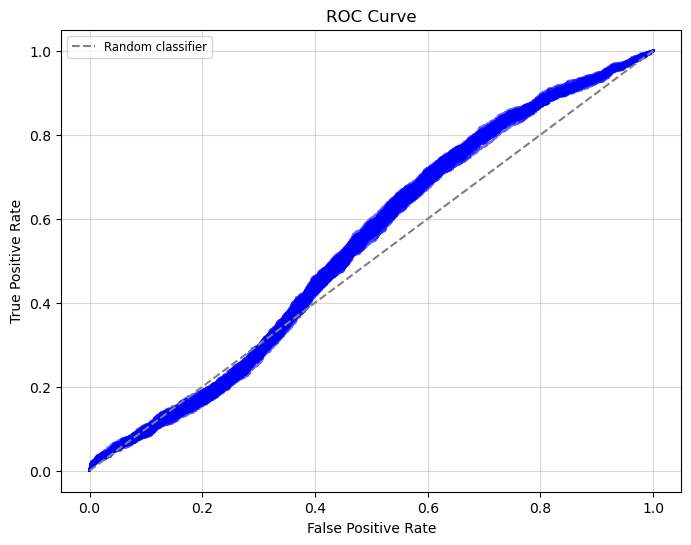

In [31]:
y = scores_oot2['y_true'].to_numpy()
score = scores_oot2['y_pred'].to_numpy()

n_bootstrap = 100
rng = np.random.default_rng(42)
aucs = []

plt.figure(figsize=(8, 6))

for i in tqdm(range(n_bootstrap)):
    indices = rng.choice(len(y), size=len(y), replace=True)
    y_bootstrap = y[indices]
    score_bootstrap = score[indices]

    roc_auc_bootstrap = roc_auc_score(y_bootstrap, score_bootstrap)
    aucs.append(roc_auc_bootstrap)
    fpr_bootstrap, tpr_bootstrap, _ = roc_curve(y_bootstrap, score_bootstrap)

    plt.plot(fpr_bootstrap, tpr_bootstrap, 'b', alpha=0.6)

auc_mean = np.mean(aucs)
auc_lower, auc_upper = np.percentile(aucs, [2.5, 97.5])
print(f"Mean bootstrap AUC: {auc_mean:.4f}")
print(f"95% confidence interval: [{auc_lower:.4f}, {auc_upper:.4f}]")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(fontsize="small")
plt.grid(alpha=0.5)
plt.show()